In [63]:
#import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

#path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset.csv"
#df = pd.read_csv(path, sep=r'\s+', low_memory=False)
#print(df.head())
#column_data = df['REGION'] 

#print(repr(column_data.tolist())) 
#region = df.get('REGION', 'Unknown')
#print(region)


# --- 1. Exclude Puerto Rico ---
#df_filtered = df[df["REGION"] !='Puerto Rico'].copy()
#print("1. Filtered out data for Puerto Rico.")


#print (df)

import pandas as pd

# Load the dataset from the specified file path
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset.csv"
df = pd.read_csv(path)

# It's a good practice to clean column names by stripping any leading/trailing whitespace
df.columns = df.columns.str.strip()

# Display the original number of rows for context
print(f"Original number of rows: {len(df)}")

# Filter the DataFrame to exclude any rows where the 'REGION NAME' is 'Puerto Rico'
# A new DataFrame is created to store the filtered data.
df_filtered = df[df['REGION NAME'] != 'Puerto Rico'].copy()

# Display the number of rows after the filtering operation
print(f"Number of rows after excluding Puerto Rico: {len(df_filtered)}")

# To verify, let's look at the first few rows of the filtered data
print("\nFirst 5 rows of the filtered data:")
print(df_filtered.head())

# And confirm that 'Puerto Rico' is no longer in the 'REGION NAME' column
print("\nUnique values in 'REGION NAME' after filtering:")
print(df_filtered['REGION NAME'].unique())

df.to_csv(r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv", index=False)

Original number of rows: 43260
Number of rows after excluding Puerto Rico: 42655

First 5 rows of the filtered data:
  FREQUENCY PERIOD BEGIN PERIOD END REGION NAME  PROPERTY TYPE INCOME GROUP  \
0   Monthly     6/1/2026  6/30/2026     Alabama  Single Family    Homeowner   
1   Monthly     5/1/2026  5/31/2026     Alabama  Single Family    Homeowner   
2   Monthly     4/1/2026  4/30/2026     Alabama  Single Family    Homeowner   
3   Monthly     3/1/2026  3/31/2026     Alabama  Single Family    Homeowner   
4   Monthly     2/1/2026  2/28/2026     Alabama  Single Family    Homeowner   

   DOWN PAYMENT PERCENT (%)  INCOME REQUIRED ($)  INCOME REQUIRED YOY (%)  \
0                       3.5              90532.0                    -1.49   
1                       3.5              90652.0                    -0.56   
2                       3.5              88160.0                     0.65   
3                       3.5              86472.0                    -1.26   
4                      

Pearson Correlation Coefficient (r): 0.9705
Coefficient of Determination (R-squared): 0.9419


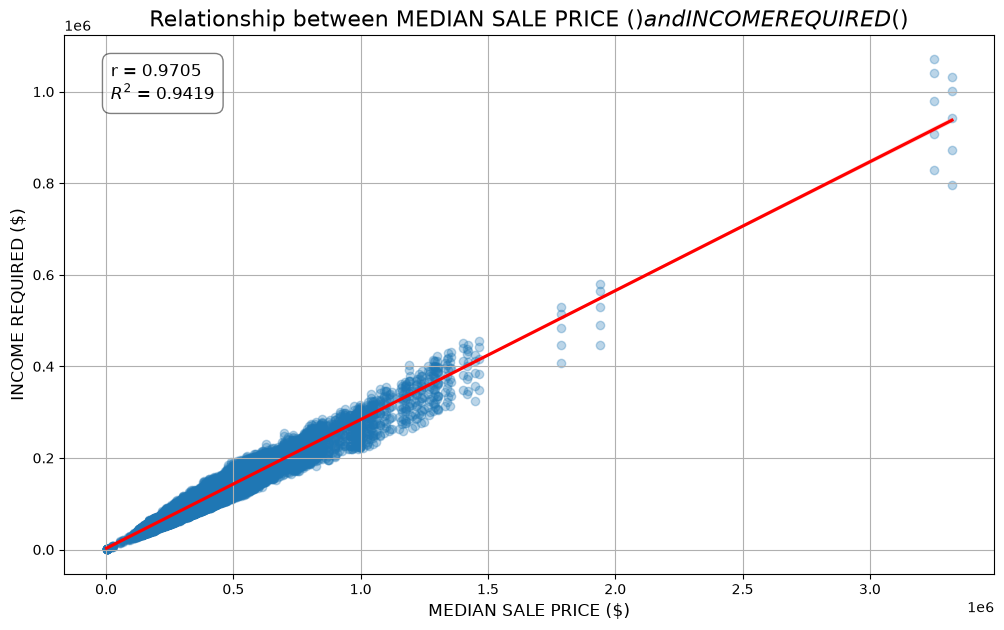

In [66]:
#Selects Variables: Chooses MEDIAN SALE PRICE ($) and INCOME REQUIRED ($) for the analysis and removes any rows with missing values in these columns.

#Calculates Correlation: Computes the Pearson correlation coefficient (r) and the coefficient of determination (R-squared).

#Generates Plot: Creates a scatter plot of the two variables and adds a linear regression trend line to visualize the relationship.


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)

# Define the independent (X) and dependent (Y) variables
x_var = 'MEDIAN SALE PRICE ($)'
y_var = 'INCOME REQUIRED ($)'
x = df_regression[x_var]
y = df_regression[y_var]

# 5. Calculate Pearson correlation coefficient (r) and the Coefficient of Determination (R-squared)
r, _ = stats.pearsonr(x, y)
r_squared = r**2

print(f"Pearson Correlation Coefficient (r): {r:.4f}")
print(f"Coefficient of Determination (R-squared): {r_squared:.4f}")

# 6. Create the scatterplot with a regression line to visualize the linear relationship
plt.figure(figsize=(12, 7))
sns.regplot(x=x, y=y, line_kws={"color":"red"}, scatter_kws={"alpha":0.3})

# 7. Add titles and labels for clarity
plt.title(f'Relationship between {x_var} and {y_var}', fontsize=16)
plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.grid(True)

# Add the correlation values as an annotation on the plot
plt.text(0.05, 0.95, f'r = {r:.4f}\n$R^2$ = {r_squared:.4f}', 
         transform=plt.gca().transAxes, 
         fontsize=12, 
         verticalalignment='top', 
         bbox=dict(boxstyle='round,pad=0.5', fc='white', alpha=0.5))

# Display the final plot
plt.show()


The incredibly strong linear relationship (r=0.9705, R^2 =0.9419) between Median Sale Price and Required Income reveals critical structural elements of the housing market:

With R^2 at 94% this shows you can confidently predict the income required to purchase a home in any region simply by knowing its median sale price. This allows policymakers and analysts to model local affordability using a single independent variable.

Fixed Affordability Thresholds: The near-perfect linearity suggests that financial underwriting standards (such as debt-to-income ratios) are applied uniformly across all price levels. There is no "plateau" at the higher end, meaning high-income buyers are subject to the same structural constraint proportions as middle-income buyers.



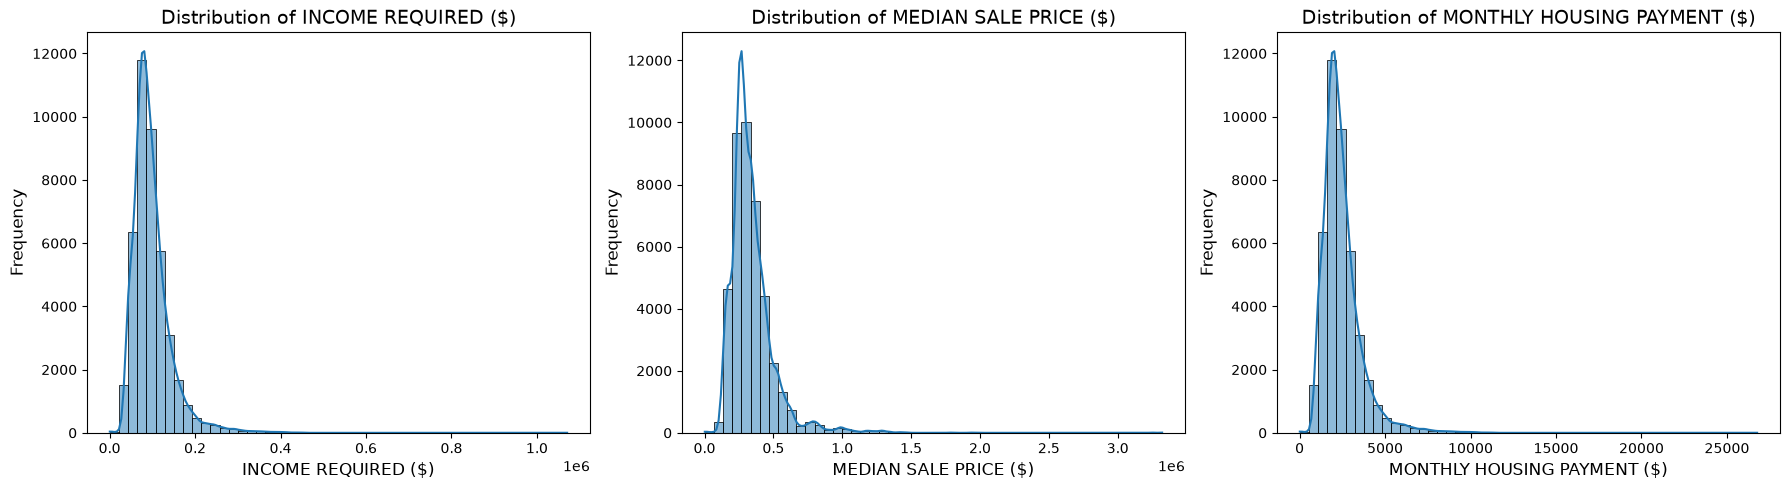

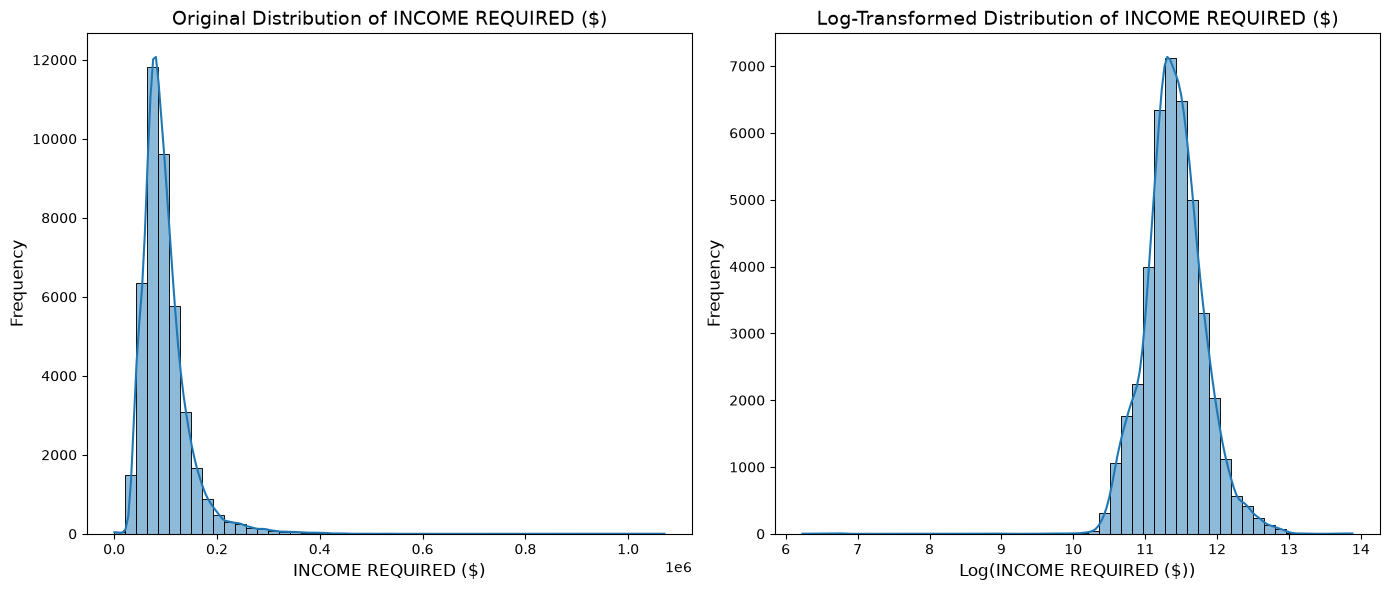

In [67]:
#Histograms and Transformation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)


# Identify the response variables to analyze
response_vars = [
    'INCOME REQUIRED ($)',
    'MEDIAN SALE PRICE ($)',
    'MONTHLY HOUSING PAYMENT ($)'
]

# Create a figure to hold the subplots for each variable
plt.figure(figsize=(18, 5))

# Loop through each variable and plot its histogram with a KDE curve
for i, var in enumerate(response_vars, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df_filtered[var].dropna(), kde=True, bins=50)
    plt.title(f'Distribution of {var}', fontsize=14)
    plt.xlabel(var, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

# Isolate the 'INCOME REQUIRED ($)' variable for a closer look
income_required = df_filtered['INCOME REQUIRED ($)'].dropna()

# Apply a log transformation to see if it normalizes the distribution
log_income_required = np.log(income_required)

# Create a new figure to compare the original vs. transformed distributions
plt.figure(figsize=(14, 6))

# Plot the original distribution
plt.subplot(1, 2, 1)
sns.histplot(income_required, kde=True, bins=50)
plt.title('Original Distribution of INCOME REQUIRED ($)', fontsize=14)
plt.xlabel('INCOME REQUIRED ($)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Plot the log-transformed distribution
plt.subplot(1, 2, 2)
sns.histplot(log_income_required, kde=True, bins=50)
plt.title('Log-Transformed Distribution of INCOME REQUIRED ($)', fontsize=14)
plt.xlabel('Log(INCOME REQUIRED ($))', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()



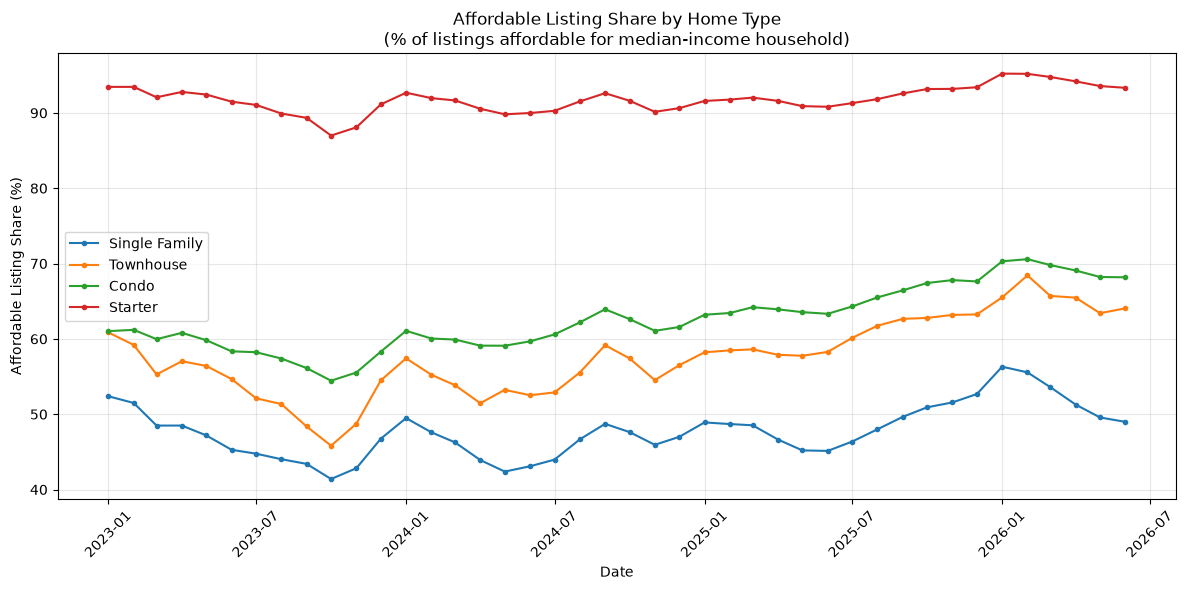

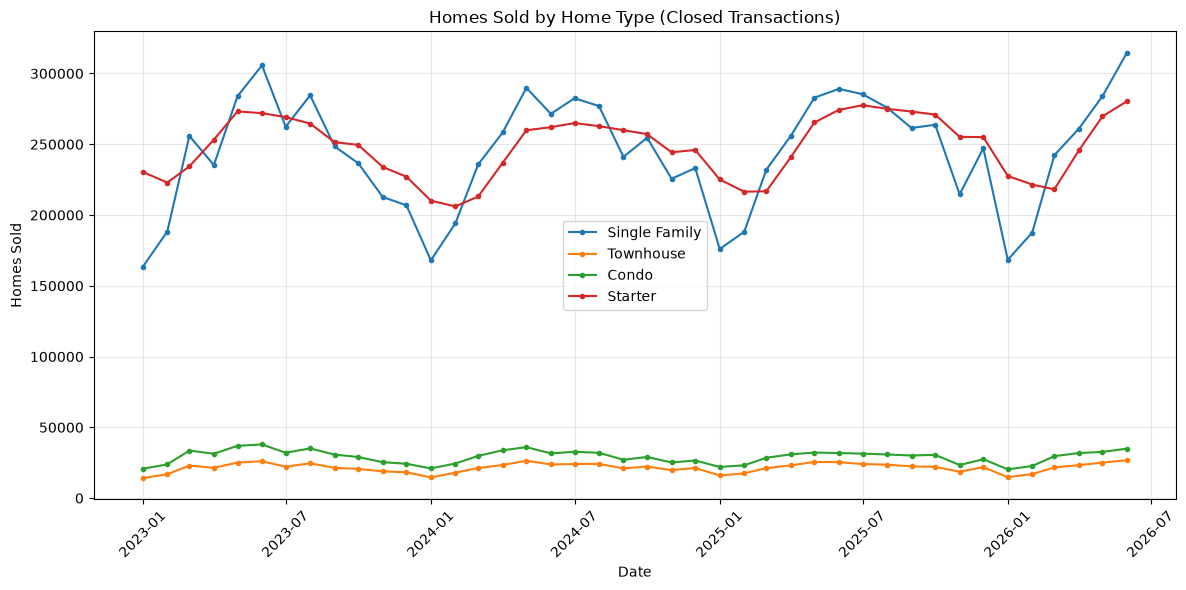

In [87]:

#converts the 'SOLD DATE' and 'LIST DATE' columns to a proper datetime format and extracts the month for time series aggregation.

#Defines Affordability: Since the dataset does not contain median income data, an affordability threshold is set at a price of $250,000. A new column IS_AFFORDABLE is created to flag properties that meet this criterion.

#Generates Plot 1 (Affordable Listing Share): It calculates the percentage of affordable homes listed each month for each of the specified home types and plots this as a time series.

#Generates Plot 2 (Homes Sold): It counts the total number of "Sold" homes for each month and home type and visualizes this trend over time.

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)

# Create proper datetime
df["Date"] = pd.to_datetime(df["Year-Month"] + "-01")

# Optional: focus on one down-payment scenario (e.g. 20%) to avoid duplicates
# (Homes Sold is identical across DP%; Affordable Share differs by DP%)
df = df[df["DOWN PAYMENT PERCENT (%)"] == 20].copy()

# Map names for cleaner legend
type_map = {
    "Single Family": "Single Family",
    "Townhouse": "Townhouse",
    "Condo/Co-op": "Condo",
    "Starter Home": "Starter"
}
df["Home Type"] = df["PROPERTY TYPE"].map(type_map)

# -------------------------------------------------
# 1. Affordable Listing Share (national average)
# -------------------------------------------------
afford = (df.groupby(["Date", "Home Type"])["AFFORDABLE LISTING SHARE (%)"]
            .mean()
            .reset_index())

plt.figure(figsize=(12, 6))
for home_type in ["Single Family", "Townhouse", "Condo", "Starter"]:
    subset = afford[afford["Home Type"] == home_type]
    plt.plot(subset["Date"], subset["AFFORDABLE LISTING SHARE (%)"],
             label=home_type, marker="o", markersize=3, linewidth=1.5)

plt.title("Affordable Listing Share by Home Type\n(% of listings affordable for median-income household)")
plt.ylabel("Affordable Listing Share (%)")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -------------------------------------------------
# 2. Homes Sold (national total)
# -------------------------------------------------
sold = (df.groupby(["Date", "Home Type"])["HOMES SOLD"]
          .sum()
          .reset_index())

plt.figure(figsize=(12, 6))
for home_type in ["Single Family", "Townhouse", "Condo", "Starter"]:
    subset = sold[sold["Home Type"] == home_type]
    plt.plot(subset["Date"], subset["HOMES SOLD"],
             label=home_type, marker="o", markersize=3, linewidth=1.5)

plt.title("Homes Sold by Home Type (Closed Transactions)")
plt.ylabel("Homes Sold")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Analysis of State-Level Data:
Pearson Correlation Coefficient (r): -0.1810
Coefficient of Determination (R-squared): 0.0327


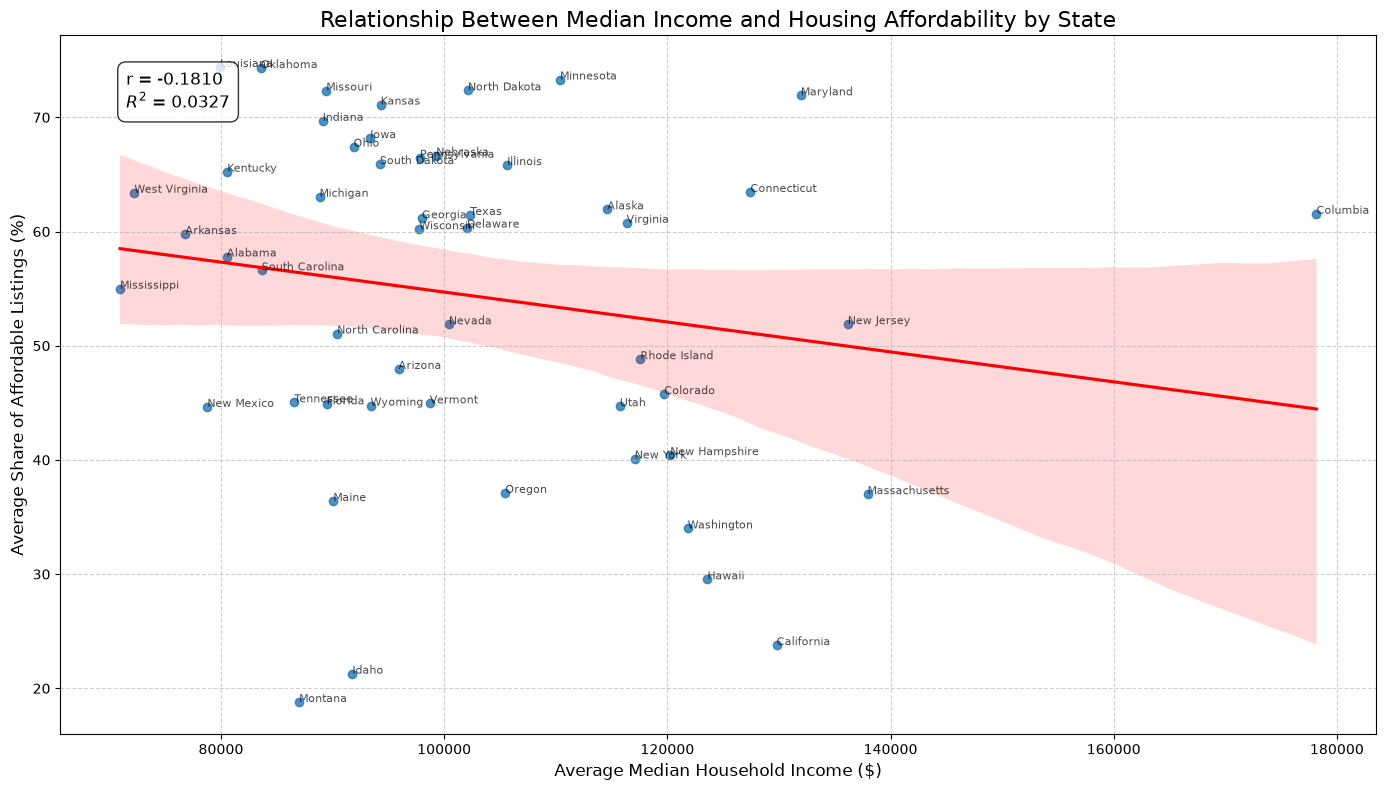

In [70]:
#Calculating house affordability based on a state's median household income
#Typically, the standard is that a household should spend no more than 28% of their gross monthly income on housing costs (principal, interest, taxes, insurance, and PMI).
#Aggregate the data by state to get a single average value for both median income and affordable listing share for each state.

#Create a scatter plot to visualize the relationship between these two variables.

#Calculate the correlation coefficient (r) and R-squared value to quantify the strength and nature of this relationship.


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)

# 2. Aggregate the data by state ('REGION NAME') to get a single representative value per state.
# We calculate the mean of the relevant columns for each state across the entire time period.
state_agg = df_filtered.groupby('REGION NAME').agg({
    'MEDIAN HOUSEHOLD INCOME ($)': 'mean',
    'AFFORDABLE LISTING SHARE (%)': 'mean'
}).reset_index()

# 3. Define the variables for the scatter plot
x_var = 'MEDIAN HOUSEHOLD INCOME ($)'
y_var = 'AFFORDABLE LISTING SHARE (%)'
x = state_agg[x_var]
y = state_agg[y_var]

# 4. Calculate the Pearson correlation coefficient (r) and R-squared value
r, _ = stats.pearsonr(x, y)
r_squared = r**2

print(f"Analysis of State-Level Data:")
print(f"Pearson Correlation Coefficient (r): {r:.4f}")
print(f"Coefficient of Determination (R-squared): {r_squared:.4f}")

# 5. Create a scatterplot to visualize the relationship
plt.figure(figsize=(14, 8))
sns.regplot(x=x, y=y, line_kws={"color":"red"})

# Add labels for each point on the plot to identify the states
for i, row in state_agg.iterrows():
    plt.text(row[x_var], row[y_var], row['REGION NAME'], fontsize=8, alpha=0.7)

# Format the plot
plt.title('Relationship Between Median Income and Housing Affordability by State', fontsize=16)
plt.xlabel('Average Median Household Income ($)', fontsize=12)
plt.ylabel('Average Share of Affordable Listings (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Add the correlation values as an annotation
plt.text(0.05, 0.95, f'r = {r:.4f}\n$R^2$ = {r_squared:.4f}',
         transform=plt.gca().transAxes,
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', fc='white', alpha=0.8))

plt.tight_layout()
plt.show()


Analyzing data for the most recent period: June 2026


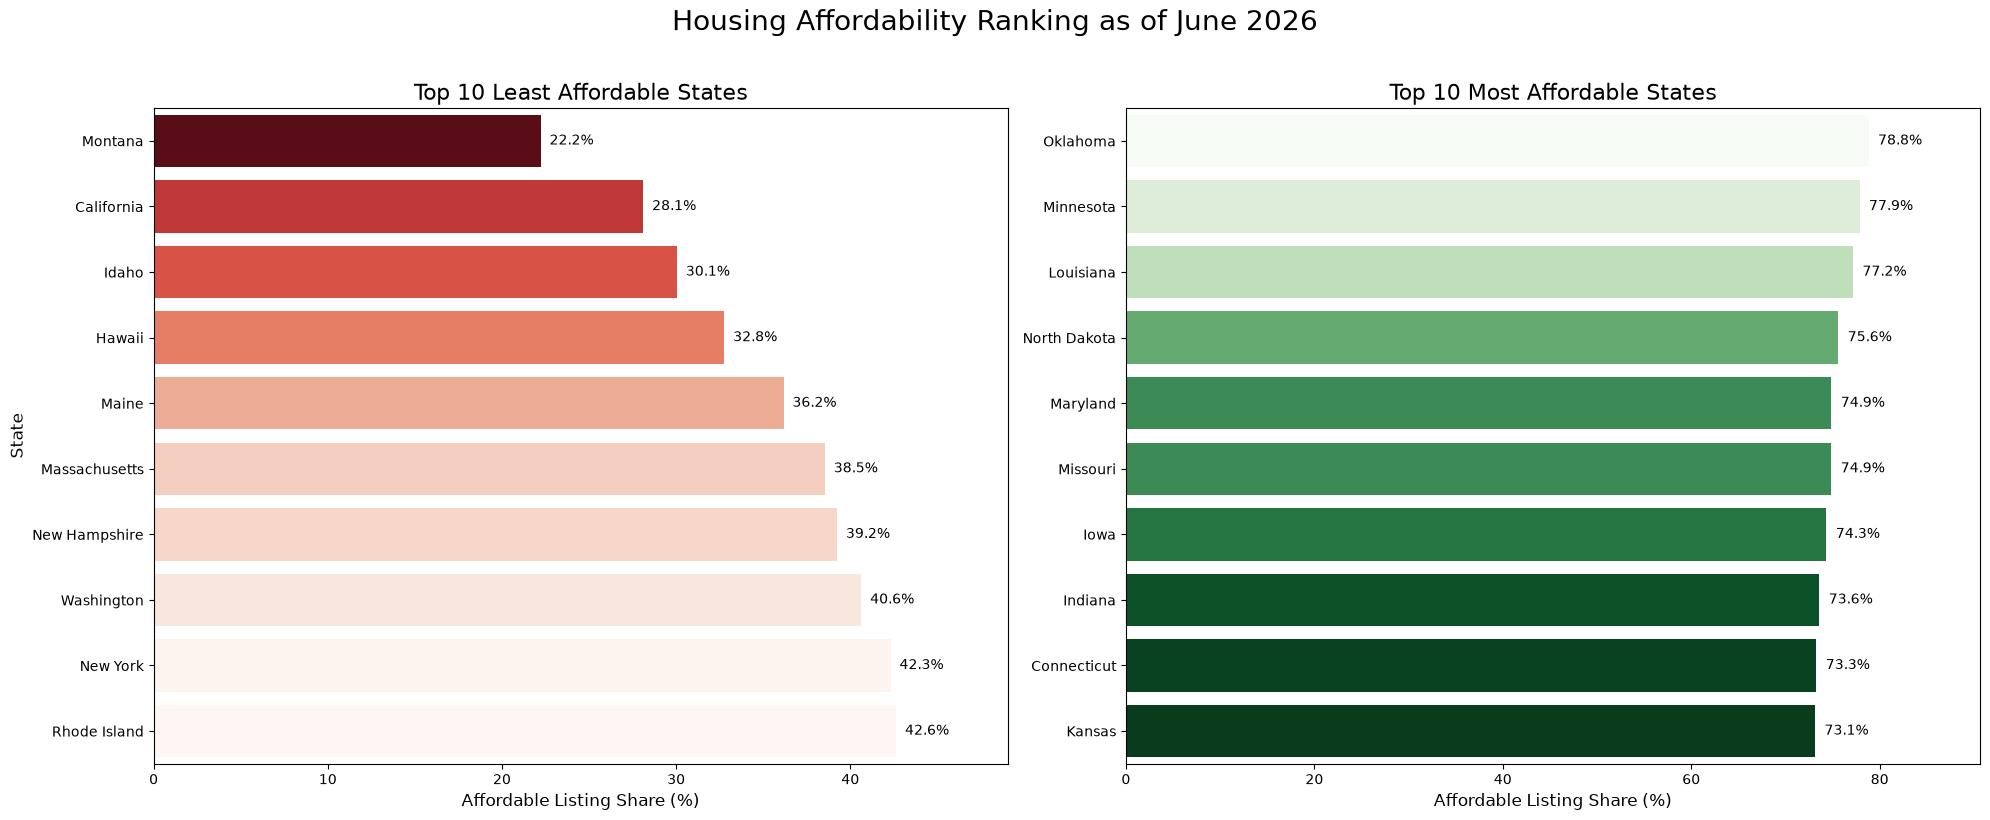

In [82]:
#Analysis of Affordability Rankings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)

# 2. Convert 'PERIOD BEGIN' to datetime and find the most recent date
df_filtered['PERIOD BEGIN'] = pd.to_datetime(df_filtered['PERIOD BEGIN'])
most_recent_date = df_filtered['PERIOD BEGIN'].max()

print(f"Analyzing data for the most recent period: {most_recent_date.strftime('%B %Y')}")

# 3. Filter the DataFrame to include only data from the most recent period
recent_data = df_filtered[df_filtered['PERIOD BEGIN'] == most_recent_date]

# 4. Group by state, calculate the mean affordable listing share, and sort the results
# The mean is used to get a single value per state for the period, in case of multiple property types.
state_affordability = recent_data.groupby('REGION NAME')['AFFORDABLE LISTING SHARE (%)'].mean().sort_values()

# 5. Identify the top 10 least and most affordable states
least_affordable = state_affordability.head(10)
most_affordable = state_affordability.tail(10).sort_values(ascending=False)

# 6. Create the plots
plt.figure(figsize=(20, 8))

# --- Plot for the 10 Least Affordable States ---
plt.subplot(1, 2, 1)
#ax1 = sns.barplot(x=least_affordable.values, y=least_affordable.index, palette='Reds_r')

ax1 = sns.barplot(x=least_affordable.values,
                 y=least_affordable.index,
                 hue=least_affordable.values , palette ='Reds_r', legend=False )


plt.title('Top 10 Least Affordable States', fontsize=16)
plt.xlabel('Affordable Listing Share (%)', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.xlim(0, max(least_affordable.values) * 1.15) # Adjust x-axis limit for text

# Add annotations to the bars
for index, value in enumerate(least_affordable):
    ax1.text(value + 0.5, index, f'{value:.1f}%', color='black', ha='left', va='center')

# --- Plot for the 10 Most Affordable States ---
plt.subplot(1, 2, 2)
#ax2 = sns.barplot(x=most_affordable.values, y=most_affordable.index, palette='Greens_r')

ax2 = sns.barplot(x=most_affordable.values,
                 y=most_affordable.index,
                 hue=most_affordable.values , palette ='Greens_r', legend=False )

plt.title('Top 10 Most Affordable States', fontsize=16)
plt.xlabel('Affordable Listing Share (%)', fontsize=12)
plt.ylabel('') # Hide y-label as it's clear
plt.xlim(0, max(most_affordable.values) * 1.15) # Adjust x-axis limit for text

# Add annotations to the bars
for index, value in enumerate(most_affordable):
    ax2.text(value + 1, index, f'{value:.1f}%', color='black', ha='left', va='center')

plt.suptitle(f'Housing Affordability Ranking as of {most_recent_date.strftime("%B %Y")}', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()



Average Share of Income Spent on Housing by Property Type:
PROPERTY TYPE
Starter Home     22.201612
Condo/Co-op      27.536742
Townhouse        30.892388
Single Family    34.002789
Name: SHARE OF INCOME ON HOUSING (%), dtype: float64


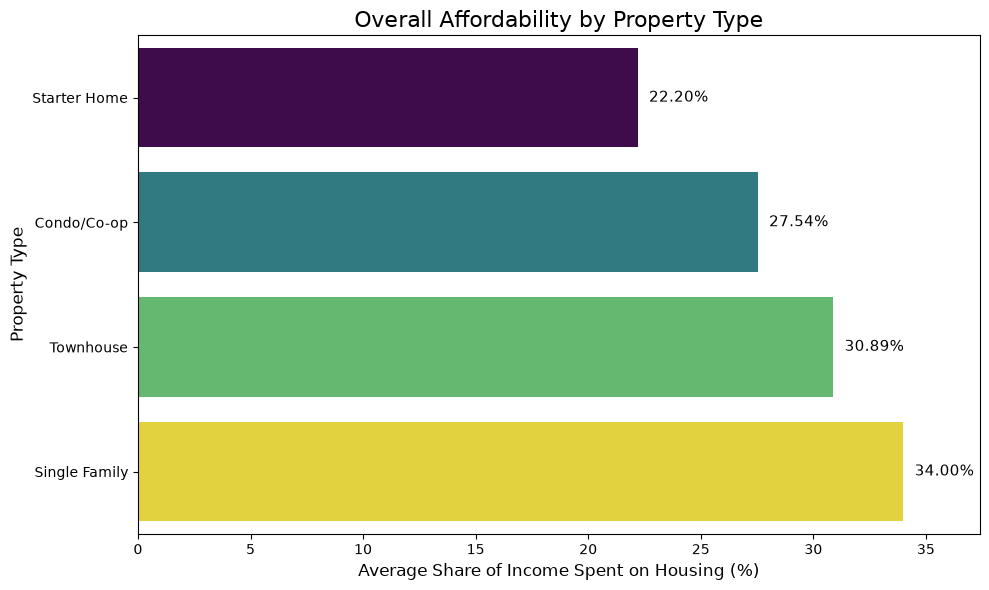

In [81]:
#Group and Aggregate: Group the data by PROPERTY TYPE and calculate the average SHARE OF INCOME ON HOUSING (%) for each category across all states and time periods to get a stable, overall measure.

#Sort for Affordability: Sort the results in ascending order. The property type with the lowest percentage will be the most affordable.

#Visualize the Results: Create a clean and clear horizontal bar chart to display the rankings. This type of chart is ideal for comparing a small number of distinct categories.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)

# 2. Group the data by 'PROPERTY TYPE' and calculate the mean 'SHARE OF INCOME ON HOUSING (%)'
# This gives an overall measure of affordability for each property type across the entire dataset.
affordability_by_type = df_filtered.groupby('PROPERTY TYPE')['SHARE OF INCOME ON HOUSING (%)'].mean().sort_values(ascending=True)

print("Average Share of Income Spent on Housing by Property Type:")
print(affordability_by_type)

# 3. Create a horizontal bar chart to visualize the results
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=affordability_by_type.values,
                 y=affordability_by_type.index,
                 hue=affordability_by_type.values , palette ='viridis', legend=False )

# 4. Add titles and labels for clarity
plt.title('Overall Affordability by Property Type', fontsize=16)
plt.xlabel('Average Share of Income Spent on Housing (%)', fontsize=12)
plt.ylabel('Property Type', fontsize=12)

# Annotate the bars with the exact percentage values
for index, value in enumerate(affordability_by_type):
    ax.text(value + 0.5, index, f'{value:.2f}%', color='black', ha='left', va='center', fontsize=11)

# Adjust x-axis to provide space for annotations
plt.xlim(0, max(affordability_by_type.values) * 1.1)

plt.tight_layout()
plt.show()


Average Years to Save for a Down Payment by Property Type:
PROPERTY TYPE
Starter Home     5.497633
Condo/Co-op      6.809584
Townhouse        7.663653
Single Family    8.417131
Name: YEARS TO SAVE DOWN PAYMENT, dtype: float64


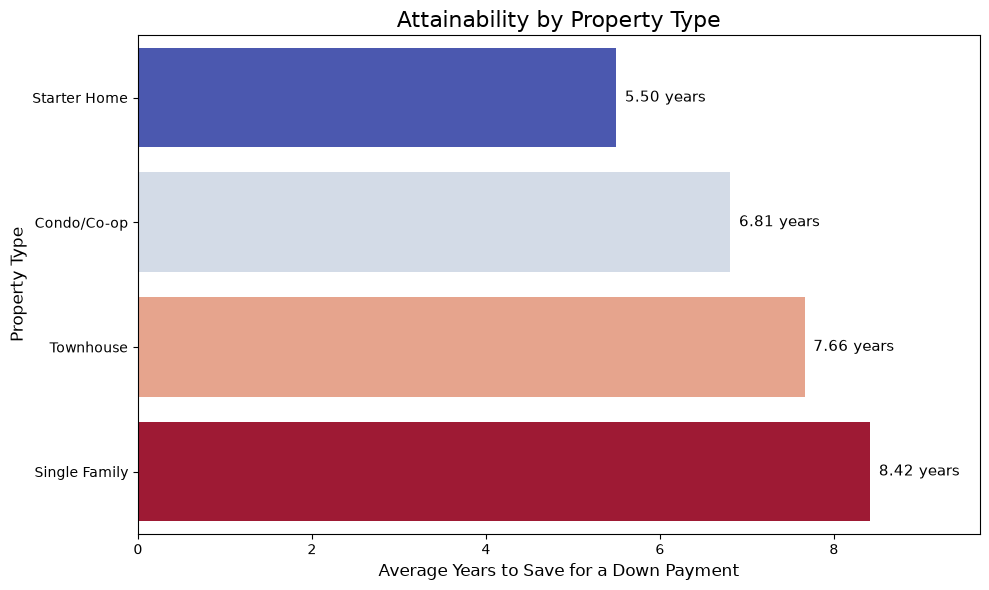

In [79]:
#calculate the average YEARS TO SAVE DOWN PAYMENT for each group. This provides a clear, overall metric for attainability.

#Sort by Attainability: The results will be sorted in ascending order. The property type requiring the fewest years to save for a down payment is the most attainable.

#Create Visualization: A horizontal bar chart is the best way to display this comparison. It provides a clear and immediate ranking of the property types from most to least attainable.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Justin Grad USD\Datasets\Team Project (Tara)\Cleaned Data sets\Combined Data Set\UpdatedCombinedPropertyDataset - No PR.csv"
df = pd.read_csv(path)


# 2. Group data by 'PROPERTY TYPE' and calculate the mean 'YEARS TO SAVE DOWN PAYMENT'
# This metric directly relates to how attainable a property is.
attainability_by_type = df_filtered.groupby('PROPERTY TYPE')['YEARS TO SAVE DOWN PAYMENT'].mean().sort_values(ascending=True)

print("Average Years to Save for a Down Payment by Property Type:")
print(attainability_by_type)

# 3. Create a horizontal bar chart for clear visualization
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=attainability_by_type.values, y=attainability_by_type.index,
            hue=attainability_by_type.values, palette='coolwarm', legend=False)

# 4. Add titles and labels for context and clarity
plt.title('Attainability by Property Type', fontsize=16)
plt.xlabel('Average Years to Save for a Down Payment', fontsize=12)
plt.ylabel('Property Type', fontsize=12)

# Annotate each bar with the precise value for better understanding
for index, value in enumerate(attainability_by_type):
    ax.text(value + 0.1, index, f'{value:.2f} years', color='black', ha='left', va='center', fontsize=11)

# Adjust the x-axis limit to ensure annotations fit
plt.xlim(0, max(attainability_by_type.values) * 1.15)

plt.tight_layout()
plt.show()


